# Calibration of the `ddeco` core

The notebook is a layer **on top of** the `ddeco` package: simulation logic lives in `ddeco/`, here are only
runs, plots and parameter fitting. If you change the model, edit `ddeco/`, not the cells.

For now we check the single-node price–stock–production loop (MODEL.md §6) and compare the convergence
rate with the spectral radii from the §6.3 table.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # run from notebooks/
import numpy as np
import matplotlib.pyplot as plt

from ddeco.tick import step_day
from tests.single_node import single_node_world, perturbed_state, NODE, GOOD

In [2]:
def trajectory(alpha, beta, eps, T, ratio=0.8, lam=0.3, days=400):
    world = single_node_world(alpha, beta, eps, T, lam=lam)
    state, star = perturbed_state(world, ratio)
    s, m = [], []
    for _ in range(days):
        step_day(world, state)
        s.append(state.stock[(NODE, GOOD)] / star)
        m.append(state.multiplier[(NODE, GOOD)])
    return np.array(s), np.array(m)

# (name, α, β, ε, T, predicted ρ from §6.3)
CATS = [
    ('necessity', 0.5, 0.3, 0.2, 10, 0.973),
    ('common',    1.0, 0.3, 0.6, 10, 0.837),
    ('luxury',    1.5, 0.3, 1.5, 14, 0.837),
]

## Convergence of the stock to target (s/s* → 1) after a −20% perturbation

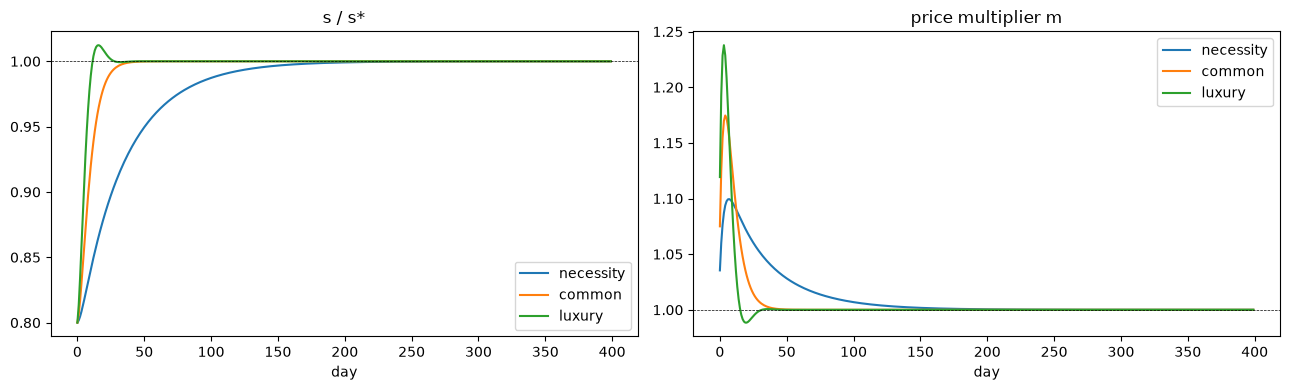

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for name, a, b, e, T, _ in CATS:
    s, m = trajectory(a, b, e, T)
    ax1.plot(s, label=name)
    ax2.plot(m, label=name)
ax1.axhline(1.0, color='k', lw=0.5, ls='--'); ax1.set_title('s / s*'); ax1.set_xlabel('day'); ax1.legend()
ax2.axhline(1.0, color='k', lw=0.5, ls='--'); ax2.set_title('price multiplier m'); ax2.set_xlabel('day'); ax2.legend()
plt.tight_layout(); plt.show()

## Convergence rate vs the §6.3 spectral radius

The deviation |s/s* − 1| should fall as ρ^t. We plot on a log scale; the slope = ln ρ.
For `necessity` the measured ρ ≈ 0.973 matches the table; `common`/`luxury` decay
faster (oscillating) and reach machine zero in ~200 days.

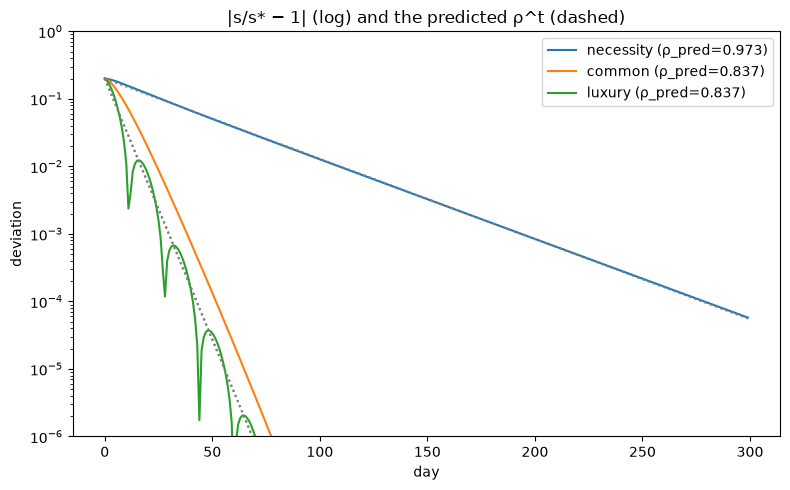

In [4]:
plt.figure(figsize=(8, 5))
for name, a, b, e, T, rho in CATS:
    s, _ = trajectory(a, b, e, T, days=300)
    dev = np.abs(s - 1.0)
    plt.semilogy(dev, label=f'{name} (ρ_pred={rho})')
    plt.semilogy(dev[0] * rho ** np.arange(len(dev)), ls=':', color='gray')
plt.title('|s/s* − 1| (log) and the predicted ρ^t (dashed)')
plt.xlabel('day'); plt.ylabel('deviation'); plt.ylim(1e-6, 1); plt.legend()
plt.tight_layout(); plt.show()

## Sandbox: the effect of λ on oscillations

A stress category (α=2, β=0.5, ε=1.5, T=2 → a=2) at the stability edge: with λ=1 —
undamped oscillations, with λ=0.5 — they decay (§6.3).

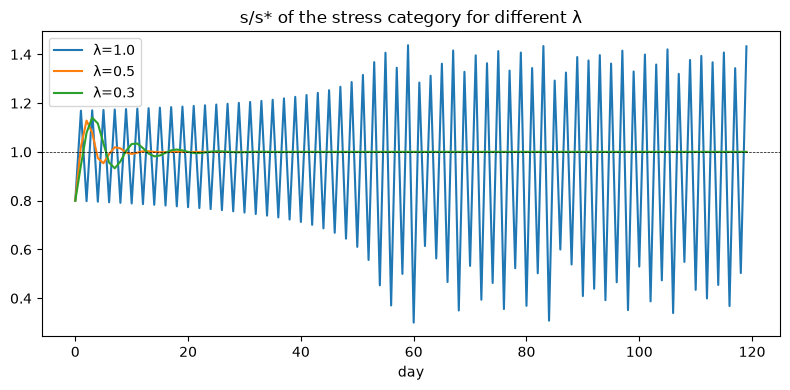

In [5]:
plt.figure(figsize=(8, 4))
for lam in (1.0, 0.5, 0.3):
    s, _ = trajectory(2.0, 0.5, 1.5, 2.0, lam=lam, days=120)
    plt.plot(s, label=f'λ={lam}')
plt.axhline(1.0, color='k', lw=0.5, ls='--'); plt.title('s/s* of the stress category for different λ')
plt.xlabel('day'); plt.legend(); plt.tight_layout(); plt.show()